In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve


In [19]:

# 1. Load the WHO Dataset
df = pd.read_csv('../data/WHO.csv')


In [20]:

# --- DATA PREPROCESSING & CLEANING ---

# Step A: Define the Target Variable
# We create a binary classification problem: "Is Life Expectancy High or Low?"
# We use the median to split the data evenly (High = 1, Low = 0)
target_col = 'Life expectancy at birth (years) both sexes'

# Drop rows where the target itself is missing
df = df.dropna(subset=[target_col])

# Create the binary target
threshold = df[target_col].median()
df['High_Life_Expectancy'] = (df[target_col] > threshold).astype(int)
print(f"Target Created: 'High_Life_Expectancy' (Threshold: > {threshold} years)")


Target Created: 'High_Life_Expectancy' (Threshold: > 70.0 years)


In [21]:

# Step B: Feature Selection
# 1. Remove ID columns
cols_to_drop = ['Country', 'CountryID']

# 2. Remove "Leakage" columns (Columns that ARE the answer, just in different units)
# e.g., "Life expectancy female", "HALE" (Healthy Life Expectancy)
leakage_cols = [c for c in df.columns if 'Life expectancy' in c and c != target_col]
leakage_cols += [c for c in df.columns if 'HALE' in c] 
cols_to_drop.extend(leakage_cols)

# 3. Drop the original continuous target
cols_to_drop.append(target_col)

# Apply drops
df_clean = df.drop(cols_to_drop, axis=1, errors='ignore')


In [22]:

# Step C: Handling Missing Values (Crucial for WHO Data)
# Drop columns that have more than 40% missing values (Too sparse to be useful)
limit = len(df_clean) * 0.6
df_clean = df_clean.dropna(thresh=limit, axis=1)

# Encode Categorical Variables (e.g., Continent)
if 'Continent' in df_clean.columns:
    le = LabelEncoder()
    df_clean['Continent'] = le.fit_transform(df_clean['Continent'].astype(str))

# Impute remaining missing values with the Median
imputer = SimpleImputer(strategy='median')
df_imputed = pd.DataFrame(imputer.fit_transform(df_clean), columns=df_clean.columns)

# Separate Features (X) and Target (y)
y = df_imputed['High_Life_Expectancy']
X = df_imputed.drop('High_Life_Expectancy', axis=1)

print(f"Final Data Shape: {X.shape}")


Final Data Shape: (193, 240)


C:\Users\panka\AppData\Local\Temp\ipykernel_15728\3224276372.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y, palette='viridis')


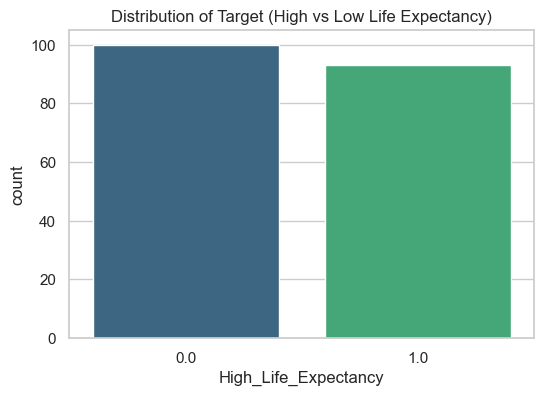

In [23]:

# --- EDA ---
# Plot 1: Target Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x=y, palette='viridis')
plt.title('Distribution of Target (High vs Low Life Expectancy)')
plt.show()


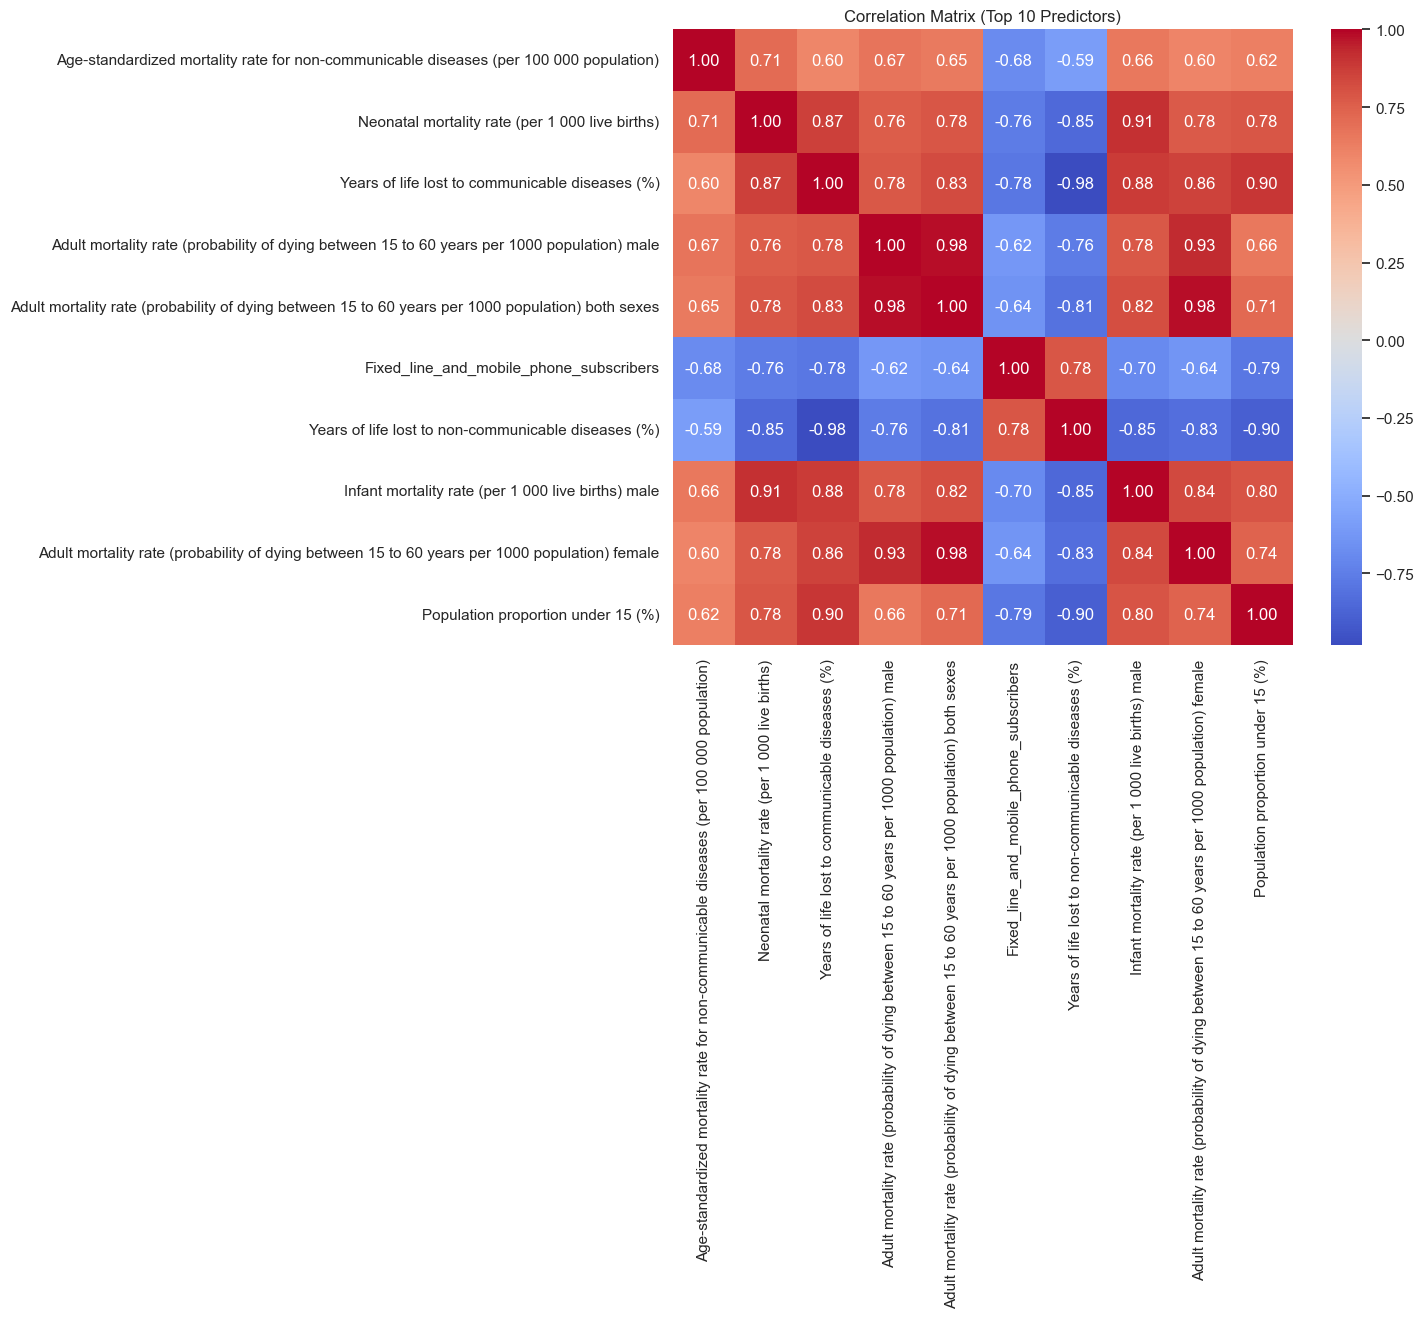

In [24]:

# Plot 2: Correlation of Top Features
# Find top 10 features most correlated with the target
correlations = df_imputed.corr()['High_Life_Expectancy'].abs().sort_values(ascending=False)
top_features = correlations.index[1:11] # Skip the first one (it's the target itself)

plt.figure(figsize=(10, 8))
sns.heatmap(df_imputed[top_features].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix (Top 10 Predictors)')
plt.show()


In [25]:

# --- MODELING ---
# Split Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale Features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [26]:

# Gradient Boosting with Hyperparameter Tuning
gbc = GradientBoostingClassifier(random_state=42)

param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 4]
}


In [27]:

print("\nStarting Hyperparameter Tuning...")
grid_search = GridSearchCV(gbc, param_grid, cv=3, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)

best_model = grid_search.best_estimator_
print("Best Parameters:", grid_search.best_params_)



Starting Hyperparameter Tuning...
Best Parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}


In [28]:

# --- EVALUATION ---
y_pred = best_model.predict(X_test_scaled)
y_prob = best_model.predict_proba(X_test_scaled)[:, 1]

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred))



--- Classification Report ---
              precision    recall  f1-score   support

         0.0       0.95      0.90      0.92        20
         1.0       0.90      0.95      0.92        19

    accuracy                           0.92        39
   macro avg       0.92      0.92      0.92        39
weighted avg       0.92      0.92      0.92        39



C:\Users\panka\AppData\Local\Temp\ipykernel_15728\885349238.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='importance', y='feature', data=feat_imp, palette='magma')


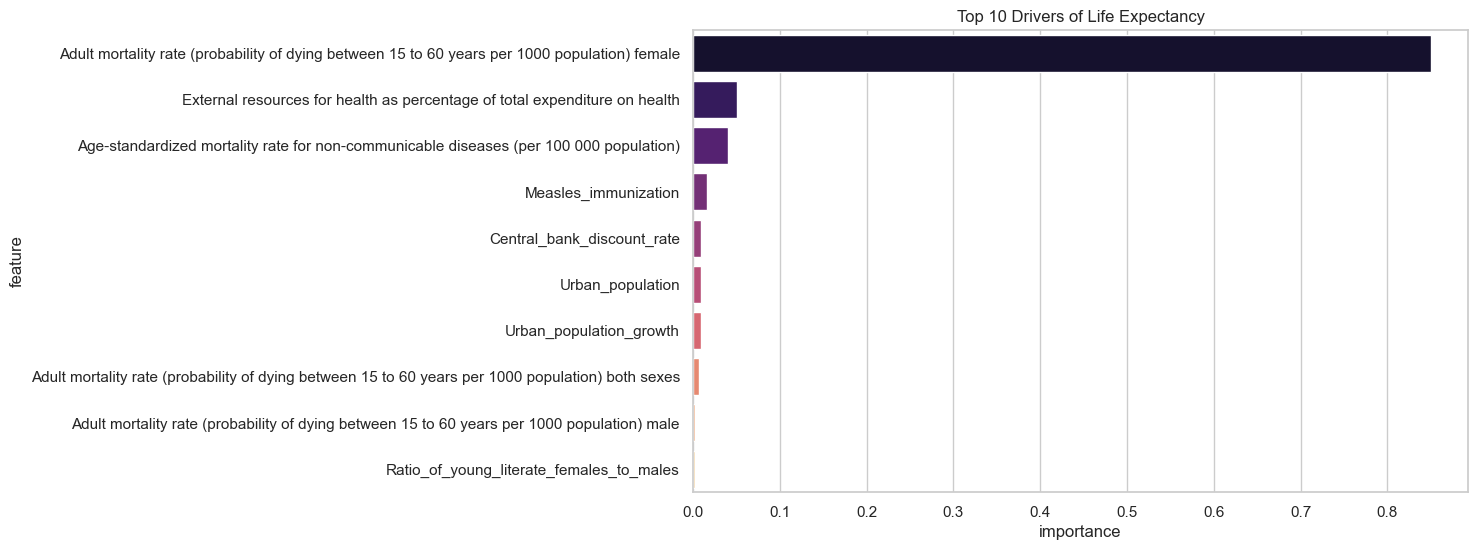

In [29]:

# Plot 3: Feature Importance
feat_imp = pd.DataFrame({'feature': X.columns, 'importance': best_model.feature_importances_})
feat_imp = feat_imp.sort_values('importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=feat_imp, palette='magma')
plt.title('Top 10 Drivers of Life Expectancy')
plt.show()


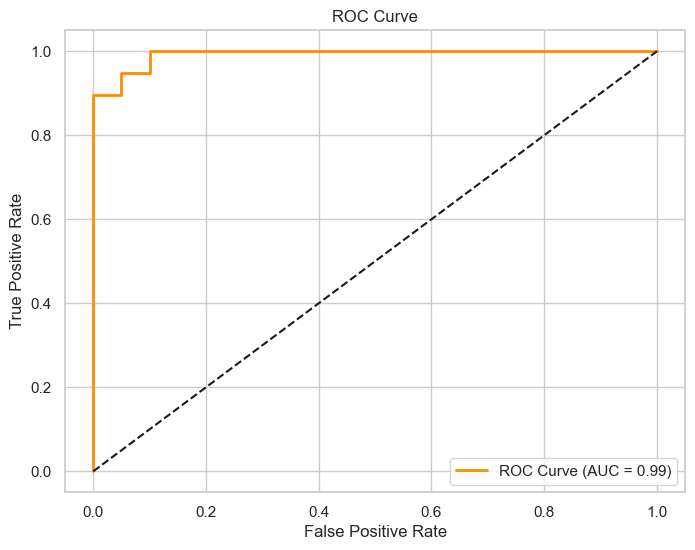

In [30]:

# Plot 4: ROC Curve
roc_auc = roc_auc_score(y_test, y_prob)
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})', color='darkorange', lw=2)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()
